# SPRINT 3: OPTIMIZATION & FINAL MODEL

## Objective

The goal of Sprint 3 is to optimize the selected regression models by performing hyperparameter tuning and selecting the best-performing model. The optimized model will then be evaluated on the unseen test dataset and serialized for deployment in Sprint 4.

This sprint includes:

- Loading the preprocessed datasets
- Hyperparameter tuning
- Building the optimized model
- Final model evaluation
- Model serialization

The output of this sprint will be the final trained model ready for deployment.

## Step 1: Load Preprocessed Data

The objective of this step is to load the preprocessed training and testing datasets generated in Sprint 1. These datasets will be used to optimize the selected regression models through hyperparameter tuning.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# Data Manipulation
import pandas as pd
import numpy as np

# Machine Learning Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Model Serialization
import joblib

In [3]:
X_train = pd.read_csv("../dataset/processed/X_train_processed.csv")
X_test = pd.read_csv("../dataset/processed/X_test_processed.csv")

y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze()

In [4]:
print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)

print("\nTraining Target :", y_train.shape)
print("Testing Target  :", y_test.shape)

Training Features : (28032, 21)
Testing Features  : (7008, 21)

Training Target : (28032,)
Testing Target  : (7008,)


In [5]:
print("Training Features")
display(X_train.head())

print("\nTesting Features")
display(X_test.head())

Training Features


,numerical__nsm,numerical__lagging_current_reactive_power_kvarh,numerical__leading_current_reactive_power_kvarh,numerical__lagging_current_power_factor,numerical__leading_current_power_factor,numerical__co2_emissions,numerical__hour,numerical__month,numerical__quarter,categorical__weekstatus_Weekend,...,categorical__day_of_week_Saturday,categorical__day_of_week_Sunday,categorical__day_of_week_Thursday,categorical__day_of_week_Tuesday,categorical__day_of_week_Wednesday,categorical__load_type_Maximum_Load,categorical__load_type_Medium_Load,categorical__season_Spring,categorical__season_Summer,categorical__season_Winter
0,0.781171,-0.798509,2.404457,1.027010,-2.147693,-0.711768,0.799911,-0.733410,-0.457435,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
1,-1.314120,-0.495515,-0.522458,-1.563027,0.513680,-0.711768,-1.369661,-0.442758,-0.457435,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,-1.458623,-0.347399,-0.522458,-0.771334,0.513680,-0.711768,-1.514299,-1.314713,-1.354513,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.239285,0.570800,-0.522458,0.663644,0.513680,1.151247,0.221358,1.591803,1.336720,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-1.314120,-0.563735,-0.522458,-0.926609,0.513680,-0.711768,-1.369661,-0.733410,-0.457435,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0



Testing Features


,numerical__nsm,numerical__lagging_current_reactive_power_kvarh,numerical__leading_current_reactive_power_kvarh,numerical__lagging_current_power_factor,numerical__leading_current_power_factor,numerical__co2_emissions,numerical__hour,numerical__month,numerical__quarter,categorical__weekstatus_Weekend,...,categorical__day_of_week_Saturday,categorical__day_of_week_Sunday,categorical__day_of_week_Thursday,categorical__day_of_week_Tuesday,categorical__day_of_week_Wednesday,categorical__load_type_Maximum_Load,categorical__load_type_Medium_Load,categorical__season_Spring,categorical__season_Summer,categorical__season_Winter
0,-0.663858,-0.563735,-0.522458,-1.075019,0.513680,-0.711768,-0.646470,-0.733410,-0.457435,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.022531,2.152758,-0.522458,-0.110621,0.513680,1.151247,0.076720,1.010499,1.336720,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.049721,2.867528,-0.522458,0.478264,0.513680,3.014262,-0.067918,-1.605365,-1.354513,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.383788,-0.798509,1.708341,1.027010,-2.158187,-0.711768,0.365997,-0.152107,-0.457435,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.456039,0.491518,-0.522458,0.720156,0.513680,1.151247,0.510635,1.591803,1.336720,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [6]:
print("Missing Values in X_train :", X_train.isnull().sum().sum())
print("Missing Values in X_test  :", X_test.isnull().sum().sum())

print("Missing Values in y_train :", y_train.isnull().sum())
print("Missing Values in y_test  :", y_test.isnull().sum())

Missing Values in X_train : 0
Missing Values in X_test  : 0
Missing Values in y_train : 0
Missing Values in y_test  : 0


## Step 2: Hyperparameter Tuning

The objective of this step is to optimize the selected regression models by identifying the best combination of hyperparameters using GridSearchCV.

Hyperparameter tuning improves model performance by systematically evaluating different parameter combinations through cross-validation.

In [7]:
models = {
    "Random Forest": {
        "model": RandomForestRegressor(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },

    "Decision Tree": {
        "model": DecisionTreeRegressor(random_state=42),
        "params": {
            "criterion": ["squared_error", "friedman_mse"],
            "max_depth": [5, 10, 20, None],
            "min_samples_split": [2, 5, 10],
            "min_samples_leaf": [1, 2, 4]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5, 7],
            "subsample": [0.8, 1.0]
        }
    }
}

In [9]:
best_models = {}
tuning_results = []

for name, config in models.items():

    grid = GridSearchCV(
        estimator=config["model"],
        param_grid=config["params"],
        cv=3,
        scoring="r2",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV R²": round(grid.best_score_, 4),
        "Best Parameters": grid.best_params_
    })

tuning_results = pd.DataFrame(tuning_results)

display(tuning_results)

,Model,Best CV R²,Best Parameters
0,Random Forest,0.9985,"{'max_depth': 20, 'min_samples_leaf': 1, 'min_..."
1,Decision Tree,0.9974,"{'criterion': 'squared_error', 'max_depth': No..."
2,Gradient Boosting,0.9990,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti..."


## Step 3: Build Final Model

The objective of this step is to evaluate the optimized models obtained from hyperparameter tuning and identify the best-performing model based on its performance on the unseen test dataset.

In [10]:
final_results = []

for name, model in best_models.items():

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    final_results.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, y_train_pred),
        "Test MAE": mean_absolute_error(y_test, y_test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, y_train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "Train R²": r2_score(y_train, y_train_pred),
        "Test R²": r2_score(y_test, y_test_pred)
    })

final_results = pd.DataFrame(final_results).round(4)

display(final_results)

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²
0,Random Forest,0.1399,0.3596,0.4166,1.0468,0.9998,0.9990
1,Decision Tree,0.1723,0.5412,0.5632,1.5177,0.9997,0.9980
2,Gradient Boosting,0.1577,0.3464,0.2590,0.8613,0.9999,0.9993


In [11]:
final_results = final_results.sort_values(
    by="Test R²",
    ascending=False
).reset_index(drop=True)

display(final_results)

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²
0,Gradient Boosting,0.1577,0.3464,0.2590,0.8613,0.9999,0.9993
1,Random Forest,0.1399,0.3596,0.4166,1.0468,0.9998,0.9990
2,Decision Tree,0.1723,0.5412,0.5632,1.5177,0.9997,0.9980


In [12]:
best_model_name = final_results.loc[0, "Model"]

final_model = best_models[best_model_name]

print(f"Final Selected Model: {best_model_name}")

Final Selected Model: Gradient Boosting


## Step 4: Final Evaluation

The objective of this step is to evaluate the final optimized model using the unseen test dataset and assess its predictive performance.

In [13]:
y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

In [14]:
final_train_mae = mean_absolute_error(y_train, y_train_pred)
final_test_mae = mean_absolute_error(y_test, y_test_pred)

final_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
final_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

final_train_r2 = r2_score(y_train, y_train_pred)
final_test_r2 = r2_score(y_test, y_test_pred)

evaluation = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [final_train_mae, final_test_mae],
    "RMSE": [final_train_rmse, final_test_rmse],
    "R² Score": [final_train_r2, final_test_r2]
}).round(4)

display(evaluation)

,Dataset,MAE,RMSE,R² Score
0,Training,0.1577,0.2590,0.9999
1,Testing,0.3464,0.8613,0.9993


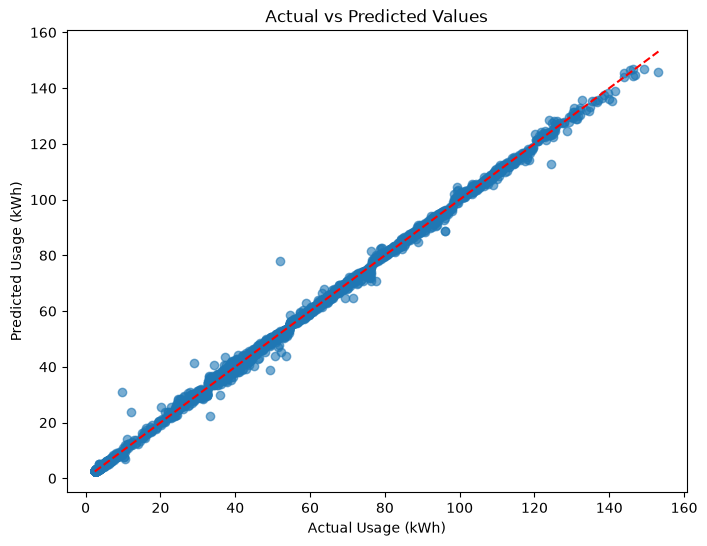

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
plt.scatter(y_test, y_test_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Usage (kWh)")
plt.ylabel("Predicted Usage (kWh)")
plt.title("Actual vs Predicted Values")

plt.show()

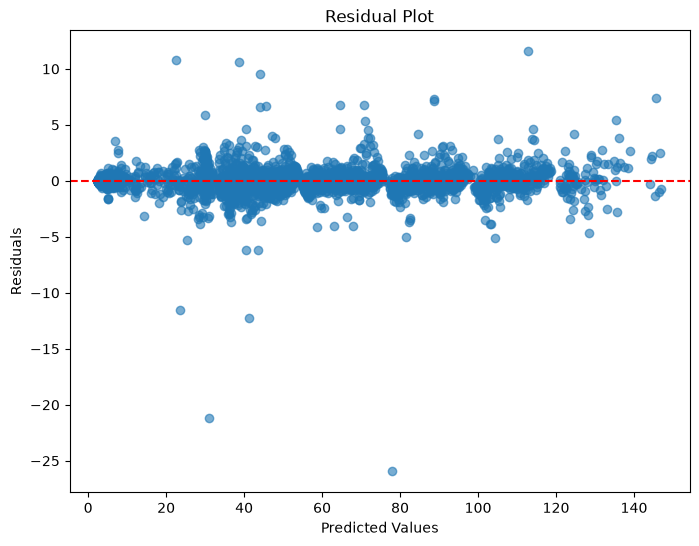

In [16]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8,6))
plt.scatter(y_test_pred, residuals, alpha=0.6)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [18]:
if hasattr(final_model, "feature_importances_"):

    feature_importance = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": final_model.feature_importances_
    }).sort_values(
        by="Importance",
        ascending=False
    )

    display(feature_importance)


,Feature,Importance
5,numerical__co2_emissions,0.972304
1,numerical__lagging_current_reactive_power_kvarh,0.018424
3,numerical__lagging_current_power_factor,0.005941
4,numerical__leading_current_power_factor,0.001291
0,numerical__nsm,0.000816
2,numerical__leading_current_reactive_power_kvarh,0.000374
7,numerical__month,0.000250
6,numerical__hour,0.000151
9,categorical__weekstatus_Weekend,0.000106
17,categorical__load_type_Medium_Load,0.000096


## Step 5: Model Serialization

The objective of this step is to save the final optimized model and preprocessing pipeline so that they can be reused for inference and deployment without retraining.

In [19]:
import os

os.makedirs("../artifacts", exist_ok=True)

In [20]:
joblib.dump(final_model, "../artifacts/final_model.joblib")

print("Final model saved successfully.")

Final model saved successfully.
